### scikit-learn 4: Unüberwachtes Lernen - Übungen

Bisher kannten die Modelle beim Training die richtigen Antworten (**überwachtes Lernen**). Beim **unüberwachten Lernen** gibt es nur die Merkmale.
Das Modell soll selbst Strukturen finden: Gruppen ähnlicher Beispiele (**Clustering**) oder wenige neue Merkmale, die das Wesentliche vieler alter enthalten
(**Dimensionsreduktion**). Zum Schluss erkennst du in einem kleinen Projekt handgeschriebene Ziffern und vergleichst dabei die Verfahren der ganzen Reihe.

Die Reihe hat vier Notebooks:

1. Grundlagen: Merkmale und Zielwerte, das erste Modell, Trainings- und Testdaten, Skalieren
2. Klassifikation: k-nächste Nachbarn, Entscheidungsbäume, logistische Regression, neuronale Netze, Kreuzvalidierung
3. Regression: Zahlen vorhersagen, Überanpassung
4. **Unüberwachtes Lernen**: Clustering, Dimensionen reduzieren, Ziffernerkennung (dieses Notebook)

Vorausgesetzt werden die Notebooks 1 und 2 der Reihe.

**Tabellen anzeigen:** Steht eine Tabelle (ein DataFrame) in der **letzten Zeile** einer Zelle, zeigt JupyterLab sie als Tabelle an. Mehrere Tabellen
in einer Zelle zeigt man mit `display(df)` an. Einzelne Werte gibt man wie gewohnt mit `print()` aus. Die erwarteten Ausgaben in den Aufgaben sehen genauso aus.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Beim ersten `import sklearn` lädt der Browser die Pakete nach. Das dauert einige Sekunden.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann die Zelle aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

#### Beispieldaten anlegen

**Führe diese Zelle zuerst aus.** Sie legt die Datei `iris.csv`: die berühmten Iris-Daten von 1936, 150 vermessene Schwertlilien von drei Arten (*setosa*, *versicolor*, *virginica*).
  Gemessen sind Länge und Breite des **Kelchblatts** und des **Blütenblatts** in cm.

Die erste Zeile blendet eine harmlose Meldung aus, die das Python im Browser sonst beim ersten Training anzeigt.

In [ ]:
import warnings
warnings.filterwarnings('ignore', message='JsProxy')   # harmlose Meldung des Browser-Pythons ausblenden

from sklearn.datasets import load_iris

iris = load_iris(as_frame=True).frame
iris.columns = ['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite', 'art']
iris['art'] = iris['art'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
iris.to_csv('iris.csv', index=False)
print('Angelegt: iris.csv')

## 1. Clustering mit KMeans

#### Gruppen finden

Beim **Clustering** sollen Punkte, die nahe beieinanderliegen, in dieselbe Gruppe (**Cluster**) kommen. Das bekannteste Verfahren ist **KMeans**:

1. Wähle `k` Startpunkte als **Mittelpunkte** der Cluster.
2. Ordne jeden Punkt dem nächsten Mittelpunkt zu.
3. Verschiebe jeden Mittelpunkt in den Schwerpunkt (Mittelwert) seiner Punkte.
4. Wiederhole 2 und 3, bis sich nichts mehr ändert.

`KMeans(n_clusters=4, n_init=10, random_state=0)`: `n_init=10` startet das Verfahren zehnmal mit verschiedenen Startpunkten und behält das beste Ergebnis.
`fit(X)` bekommt **nur** die Merkmale, kein `y`. Danach sind `labels_` die Clusternummern der Punkte (0 bis `k - 1`, die Reihenfolge ist beliebig)
und `cluster_centers_` die Mittelpunkte.

Die Übungsdaten erzeugt `make_blobs()`: Punktwolken um zufällige Zentren. Es liefert auch die „richtigen“ Gruppen, die hier mit `_` weggeworfen werden.

In [ ]:
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
import numpy as np
import matplotlib.pyplot as plt

modell = KMeans(n_clusters=4, n_init=10, random_state=0)
modell.fit(X)
print(modell.labels_[:10])
print(np.bincount(modell.labels_))
print(modell.cluster_centers_.round(2))
plt.scatter(X['x1'], X['x2'], c=modell.labels_, s=10)
plt.scatter(modell.cluster_centers_[:, 0], modell.cluster_centers_[:, 1], color='red', marker='x', s=100)
plt.show()

#### Neue Punkte zuordnen und die Güte messen

- `modell.predict(X_neu)` ordnet neue Punkte dem nächsten Mittelpunkt zu.
- `modell.inertia_` ist die Summe der quadrierten Abstände aller Punkte zu ihrem Mittelpunkt. Je kleiner, desto enger die Cluster.

In [ ]:
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])

modell = KMeans(n_clusters=4, n_init=10, random_state=0)
modell.fit(X)
neu = pd.DataFrame({'x1': [0.0, 2.0, -1.5], 'x2': [4.0, 1.0, 3.0]})
print(modell.predict(neu))
print(f'{modell.inertia_:.2f}')

#### Aufgabe 1.1

Bilde mit KMeans 3 Cluster aus den Punkten in der Zelle und gib die Anzahl der Punkte in jedem Cluster (`np.bincount()`) und die Mittelpunkte aus (2 Nachkommastellen).

**Erwartete Ausgabe:**

```
[151  77  72]
[[-0.37  3.69]
 [ 1.96  0.89]
 [-1.44  7.81]]
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
import numpy as np
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
import numpy as np
modell = KMeans(n_clusters=3, n_init=10, random_state=0)
modell.fit(X)
print(np.bincount(modell.labels_))
print(modell.cluster_centers_.round(2))
```

</details>

#### Aufgabe 1.2

Prüfe, dass jeder Mittelpunkt der Schwerpunkt seiner Punkte ist: Berechne für jedes der 4 Cluster den Mittelwert der Punkte (`X[modell.labels_ == i].mean()`)
und gib ihn neben dem Mittelpunkt aus `cluster_centers_` aus (2 Nachkommastellen).

**Erwartete Ausgabe:**

```
0 [0.85 4.44] [0.85 4.44]
1 [1.98 0.83] [1.98 0.83]
2 [-1.44  7.78] [-1.44  7.78]
3 [-1.66  2.76] [-1.66  2.76]
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
modell = KMeans(n_clusters=4, n_init=10, random_state=0)
modell.fit(X)
for i in range(4):
    print(i, X[modell.labels_ == i].mean().round(2).to_numpy(), modell.cluster_centers_[i].round(2))
```

</details>

#### Aufgabe 1.3

Ordne die Punkte (1 | 1), (−1 | 8) und (2 | 4) mit dem 4-Cluster-Modell zu und gib für jeden Punkt den Abstand zu seinem Mittelpunkt aus (`modell.transform(neu)`
liefert die Abstände zu allen Mittelpunkten, `.min(axis=1)` den kleinsten; 2 Nachkommastellen).

**Erwartete Ausgabe:**

```
[1 2 0]
[0.99 0.49 1.23]
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
modell = KMeans(n_clusters=4, n_init=10, random_state=0)
modell.fit(X)
neu = pd.DataFrame({'x1': [1, -1, 2], 'x2': [1, 8, 4]})
print(modell.predict(neu))
print(modell.transform(neu).min(axis=1).round(2))
```

</details>

#### Aufgabe 1.4

Gib für `k` von 1 bis 8 die `inertia_` aus (2 Nachkommastellen). Sie wird mit mehr Clustern immer kleiner.

**Erwartete Ausgabe:**

```
1 2978.59
2 1348.87
3 708.77
4 369.53
5 326.33
6 292.44
7 260.25
8 225.17
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
for k in range(1, 9):
    modell = KMeans(n_clusters=k, n_init=10, random_state=0)
    modell.fit(X)
    print(k, f'{modell.inertia_:.2f}')
```

</details>

#### Aufgabe 1.5

Zeichne die Punkte gefärbt nach 4 Clustern (`c=modell.labels_`, `cmap='tab10'`) und die Mittelpunkte als schwarze Sterne (`marker='*'`, `s=200`).
Setze gleiche Einheiten auf beiden Achsen (`plt.axis('equal')`).

**Erwartete Ausgabe:**



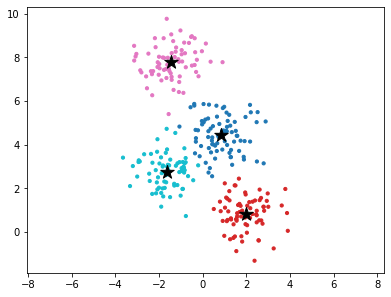

In [ ]:
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
import matplotlib.pyplot as plt
modell = KMeans(n_clusters=4, n_init=10, random_state=0)
modell.fit(X)
plt.scatter(X['x1'], X['x2'], c=modell.labels_, cmap='tab10', s=10)
plt.scatter(modell.cluster_centers_[:, 0], modell.cluster_centers_[:, 1], color='black', marker='*', s=200)
plt.axis('equal')
plt.show()
```

</details>

#### Aufgabe 1.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans

X = pd.DataFrame({'x': [1, 2, 3, 11, 12, 13]})
modell = KMeans(n_clusters=2, n_init=10, random_state=0)
modell.fit(X)
print(sorted(modell.cluster_centers_[:, 0].round(2).tolist()))
print(modell.labels_[0] == modell.labels_[2], modell.labels_[0] == modell.labels_[3])

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
[2.0, 12.0]
True False
```

Die beiden Gruppen 1, 2, 3 und 11, 12, 13 liegen weit auseinander. Ihre Mittelpunkte sind 2 und 12: `[2.0, 12.0]`.
Die Punkte 1 und 3 sind im selben Cluster, 1 und 11 nicht: `True False`.

</details>

## 2. Wie viele Cluster?

#### Ellbogen und Silhouette

Die Anzahl `k` muss man vorgeben. Wie findet man ein gutes `k`?

- **Ellbogen-Methode:** `inertia_` sinkt mit wachsendem `k` immer weiter. Man sucht den „Knick“ (den Ellbogen), ab dem mehr Cluster kaum noch etwas bringen.
- **Silhouettenkoeffizient:** `silhouette_score(X, labels)` aus `sklearn.metrics` misst für jeden Punkt, wie viel näher er an seinem eigenen Cluster liegt als am
  nächsten anderen, und mittelt das. Werte nahe 1 bedeuten gut getrennte Cluster. Man wählt das `k` mit dem größten Wert (ab `k = 2`).

In [ ]:
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

werte_k = range(1, 9)
traegheit = []
for k in werte_k:
    modell = KMeans(n_clusters=k, n_init=10, random_state=0)
    modell.fit(X)
    traegheit.append(modell.inertia_)
    if k >= 2:
        print(k, f'{silhouette_score(X, modell.labels_):.3f}')
plt.plot(werte_k, traegheit, 'o-')
plt.xlabel('k')
plt.ylabel('inertia')
plt.show()

#### Aufgabe 2.1

In der Zelle werden Punkte um eine unbekannte Anzahl von Zentren erzeugt. Gib für `k` von 2 bis 9 den Silhouettenkoeffizienten aus (3 Nachkommastellen)
und danach das beste `k`.

**Erwartete Ausgabe:**

```
2 0.663
3 0.595
4 0.577
5 0.668
6 0.554
7 0.508
8 0.518
9 0.445
5
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=500, centers=6, cluster_std=1.0, random_state=3)
X = pd.DataFrame(X, columns=['x1', 'x2'])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=500, centers=6, cluster_std=1.0, random_state=3)
X = pd.DataFrame(X, columns=['x1', 'x2'])
bestes_k = 0
beste = -1
for k in range(2, 10):
    modell = KMeans(n_clusters=k, n_init=10, random_state=0)
    modell.fit(X)
    wert = silhouette_score(X, modell.labels_)
    print(k, f'{wert:.3f}')
    if wert > beste:
        bestes_k = k
        beste = wert
print(bestes_k)
```

</details>

#### Aufgabe 2.2

Zeichne für dieselben Punkte die Ellbogen-Kurve (`inertia_` für `k` von 1 bis 10, `'o-'`) und daneben (`plt.subplot(1, 2, 2)`) die Punkte gefärbt nach dem
besten `k` aus der vorigen Aufgabe.

**Erwartete Ausgabe:**



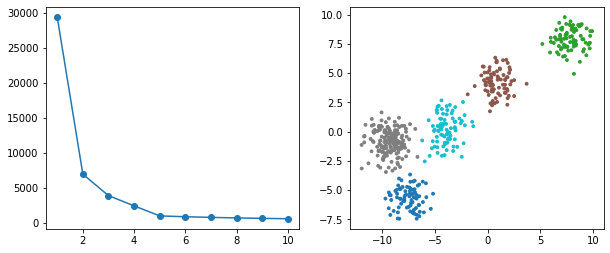

In [ ]:
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=500, centers=6, cluster_std=1.0, random_state=3)
X = pd.DataFrame(X, columns=['x1', 'x2'])
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=500, centers=6, cluster_std=1.0, random_state=3)
X = pd.DataFrame(X, columns=['x1', 'x2'])
import matplotlib.pyplot as plt
traegheit = []
for k in range(1, 11):
    modell = KMeans(n_clusters=k, n_init=10, random_state=0)
    modell.fit(X)
    traegheit.append(modell.inertia_)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, 11), traegheit, 'o-')
modell = KMeans(n_clusters=5, n_init=10, random_state=0)
modell.fit(X)
plt.subplot(1, 2, 2)
plt.scatter(X['x1'], X['x2'], c=modell.labels_, cmap='tab10', s=8)
plt.show()
```

</details>

#### Aufgabe 2.3

Wie sicher ist die Zuordnung einzelner Punkte? `silhouette_samples(X, labels)` (aus `sklearn.metrics`) gibt den Wert für jeden Punkt. Bilde 4 Cluster aus den
Punkten der Zelle und gib die Anzahl der Punkte mit negativem Wert (eher im falschen Cluster) und den kleinsten Wert aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
1
-0.014
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
from sklearn.metrics import silhouette_samples
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
from sklearn.metrics import silhouette_samples
modell = KMeans(n_clusters=4, n_init=10, random_state=0)
modell.fit(X)
werte = silhouette_samples(X, modell.labels_)
print((werte < 0).sum())
print(f'{werte.min():.3f}')
```

</details>

#### Aufgabe 2.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans

X = pd.DataFrame({'x': [1, 2, 3, 4, 5]})
modell = KMeans(n_clusters=5, n_init=10, random_state=0)
modell.fit(X)
print(modell.inertia_)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
0.0
```

Bei 5 Clustern für 5 Punkte bildet jeder Punkt sein eigenes Cluster und ist sein eigener Mittelpunkt. Alle Abstände sind 0: `0.0`.
Deshalb kann man `k` nicht einfach so wählen, dass `inertia_` am kleinsten ist.

</details>

## 3. Cluster in echten Daten

#### Ohne die Lösung

Würde KMeans die drei Iris-Arten finden, wenn man ihm die Arten nicht verrät? Man bildet Cluster nur aus den Maßen und vergleicht danach mit den Arten.
`pd.crosstab(a, b)` zählt, wie oft jede Kombination der Werte aus `a` und `b` vorkommt (eine **Kreuztabelle**). Wie bei k-NN sollte man vorher skalieren,
wenn die Merkmale sehr unterschiedliche Größenordnungen haben.

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.cluster import KMeans

modell = KMeans(n_clusters=3, n_init=10, random_state=0)
modell.fit(X)
pd.crosstab(iris['art'], modell.labels_)

#### Aufgabe 3.1

Wiederhole das Beispiel mit skalierten Iris-Maßen (`StandardScaler().fit_transform(X)`) und zeige die Kreuztabelle an.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right">col_0</th>
      <th style="text-align: right">0</th>
      <th style="text-align: right">1</th>
      <th style="text-align: right">2</th>
    </tr>
    <tr>
      <th style="text-align: right">art</th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">setosa</th>
      <td style="text-align: right">0</td>
      <td style="text-align: right">50</td>
      <td style="text-align: right">0</td>
    </tr>
    <tr>
      <th style="text-align: right">versicolor</th>
      <td style="text-align: right">39</td>
      <td style="text-align: right">0</td>
      <td style="text-align: right">11</td>
    </tr>
    <tr>
      <th style="text-align: right">virginica</th>
      <td style="text-align: right">14</td>
      <td style="text-align: right">0</td>
      <td style="text-align: right">36</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
X_skaliert = StandardScaler().fit_transform(X)
modell = KMeans(n_clusters=3, n_init=10, random_state=0)
modell.fit(X_skaliert)
pd.crosstab(iris['art'], modell.labels_)
```

</details>

#### Aufgabe 3.2

Bilde 3 Cluster aus den unskalierten Iris-Maßen und zeige die Mittelpunkte als Tabelle mit den Spaltennamen der Maße an
(`pd.DataFrame(modell.cluster_centers_, columns=X.columns)`, eine Nachkommastelle). Vergleiche mit den Mittelwerten je Art (`iris.groupby('art').mean()`).

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">kelch_laenge</th>
      <th style="text-align: right">kelch_breite</th>
      <th style="text-align: right">bluete_laenge</th>
      <th style="text-align: right">bluete_breite</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">0</th>
      <td style="text-align: right">5.9</td>
      <td style="text-align: right">2.7</td>
      <td style="text-align: right">4.4</td>
      <td style="text-align: right">1.4</td>
    </tr>
    <tr>
      <th style="text-align: right">1</th>
      <td style="text-align: right">5.0</td>
      <td style="text-align: right">3.4</td>
      <td style="text-align: right">1.5</td>
      <td style="text-align: right">0.2</td>
    </tr>
    <tr>
      <th style="text-align: right">2</th>
      <td style="text-align: right">6.8</td>
      <td style="text-align: right">3.1</td>
      <td style="text-align: right">5.7</td>
      <td style="text-align: right">2.1</td>
    </tr>
  </tbody>
</table>

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">kelch_laenge</th>
      <th style="text-align: right">kelch_breite</th>
      <th style="text-align: right">bluete_laenge</th>
      <th style="text-align: right">bluete_breite</th>
    </tr>
    <tr>
      <th style="text-align: right">art</th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">setosa</th>
      <td style="text-align: right">5.0</td>
      <td style="text-align: right">3.4</td>
      <td style="text-align: right">1.5</td>
      <td style="text-align: right">0.2</td>
    </tr>
    <tr>
      <th style="text-align: right">versicolor</th>
      <td style="text-align: right">5.9</td>
      <td style="text-align: right">2.8</td>
      <td style="text-align: right">4.3</td>
      <td style="text-align: right">1.3</td>
    </tr>
    <tr>
      <th style="text-align: right">virginica</th>
      <td style="text-align: right">6.6</td>
      <td style="text-align: right">3.0</td>
      <td style="text-align: right">5.6</td>
      <td style="text-align: right">2.0</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.cluster import KMeans
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.cluster import KMeans
modell = KMeans(n_clusters=3, n_init=10, random_state=0)
modell.fit(X)
display(pd.DataFrame(modell.cluster_centers_, columns=X.columns).round(1))
iris.groupby('art').mean().round(1)
```

</details>

#### Aufgabe 3.3

Gib für die Iris-Maße (unskaliert) den Silhouettenkoeffizienten für `k` von 2 bis 6 aus (3 Nachkommastellen). Das beste `k` ist nicht 3:
*versicolor* und *virginica* liegen so nah beieinander, dass sie eher wie ein Cluster aussehen.

**Erwartete Ausgabe:**

```
2 0.681
3 0.553
4 0.498
5 0.489
6 0.365
```

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
for k in range(2, 7):
    modell = KMeans(n_clusters=k, n_init=10, random_state=0)
    modell.fit(X)
    print(k, f'{silhouette_score(X, modell.labels_):.3f}')
```

</details>

#### Aufgabe 3.4

Bilde 3 Cluster aus den skalierten Wein-Daten (alle 13 Messwerte, `load_wine`) und zeige die Kreuztabelle mit den Anbaugebieten (`target`) an.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right">col_0</th>
      <th style="text-align: right">0</th>
      <th style="text-align: right">1</th>
      <th style="text-align: right">2</th>
    </tr>
    <tr>
      <th style="text-align: right">target</th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">0</th>
      <td style="text-align: right">0</td>
      <td style="text-align: right">0</td>
      <td style="text-align: right">59</td>
    </tr>
    <tr>
      <th style="text-align: right">1</th>
      <td style="text-align: right">65</td>
      <td style="text-align: right">3</td>
      <td style="text-align: right">3</td>
    </tr>
    <tr>
      <th style="text-align: right">2</th>
      <td style="text-align: right">0</td>
      <td style="text-align: right">48</td>
      <td style="text-align: right">0</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.cluster import KMeans
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.cluster import KMeans
X_skaliert = StandardScaler().fit_transform(X)
modell = KMeans(n_clusters=3, n_init=10, random_state=0)
modell.fit(X_skaliert)
pd.crosstab(y, modell.labels_)
```

</details>

#### Aufgabe 3.5

Zeichne die Iris-Blüten (Blütenblattlänge und -breite) zweimal nebeneinander: links gefärbt nach der Art (Zahlen 0, 1, 2 mit `iris['art'].map({...})`),
rechts nach den 3 Clustern aus allen vier unskalierten Maßen. Titel `Arten` und `Cluster`.

**Erwartete Ausgabe:**



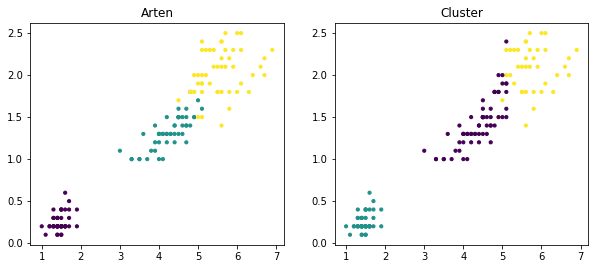

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
modell = KMeans(n_clusters=3, n_init=10, random_state=0)
modell.fit(X)
arten = iris['art'].map({'setosa': 0, 'versicolor': 1, 'virginica': 2})
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.scatter(X['bluete_laenge'], X['bluete_breite'], c=arten, s=10)
plt.title('Arten')
plt.subplot(1, 2, 2)
plt.scatter(X['bluete_laenge'], X['bluete_breite'], c=modell.labels_, s=10)
plt.title('Cluster')
plt.show()
```

</details>

## 4. Grenzen von KMeans: DBSCAN

#### Dichte statt Mittelpunkte

KMeans bildet immer runde, ähnlich große Cluster um Mittelpunkte. Bei Halbmonden geht das schief. **DBSCAN** arbeitet anders: Ein Cluster ist ein Bereich, in dem die
Punkte **dicht** liegen. Ein Punkt mit mindestens `min_samples` Nachbarn im Abstand höchstens `eps` liegt im Inneren eines Clusters; Cluster wachsen über
solche dichten Punkte weiter. Punkte, die zu keinem dichten Bereich gehören, sind **Rauschen** und bekommen die Nummer `-1`.

`DBSCAN(eps=0.2, min_samples=5)`: Die Anzahl der Cluster muss man nicht vorgeben, dafür `eps` passend zu den Abständen in den Daten wählen.

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X, _ = make_moons(n_samples=200, noise=0.06, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
kmeans.fit(X)
dbscan = DBSCAN(eps=0.2, min_samples=5)
dbscan.fit(X)
print(np.unique(dbscan.labels_))
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.scatter(X['x1'], X['x2'], c=kmeans.labels_, s=10)
plt.title('KMeans')
plt.subplot(1, 2, 2)
plt.scatter(X['x1'], X['x2'], c=dbscan.labels_, s=10)
plt.title('DBSCAN')
plt.show()

#### Aufgabe 4.1

Wende DBSCAN mit `eps=0.2` und `min_samples=5` auf die Halbmonde an. Gib die Anzahl der Cluster (ohne Rauschen) und die Anzahl der Rauschpunkte aus.
`set(labels)` enthält jede Nummer einmal.

**Erwartete Ausgabe:**

```
2
0
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X, _ = make_moons(n_samples=200, noise=0.06, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X, _ = make_moons(n_samples=200, noise=0.06, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
modell = DBSCAN(eps=0.2, min_samples=5)
modell.fit(X)
labels = modell.labels_
print(len(set(labels) - {-1}))
print((labels == -1).sum())
```

</details>

#### Aufgabe 4.2

Probiere `eps` = 0.05, 0.1, 0.2, 0.3 und 0.6 (`min_samples=5`) und gib jeweils `eps`, die Anzahl der Cluster und die Anzahl der Rauschpunkte aus.
Zu klein: fast alles ist Rauschen; zu groß: alles ist ein Cluster.

**Erwartete Ausgabe:**

```
0.05 0 200
0.1 18 55
0.2 2 0
0.3 1 0
0.6 1 0
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X, _ = make_moons(n_samples=200, noise=0.06, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X, _ = make_moons(n_samples=200, noise=0.06, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
for eps in [0.05, 0.1, 0.2, 0.3, 0.6]:
    modell = DBSCAN(eps=eps, min_samples=5)
    modell.fit(X)
    labels = modell.labels_
    print(eps, len(set(labels) - {-1}), (labels == -1).sum())
```

</details>

#### Aufgabe 4.3

Vergleiche KMeans (2 Cluster) und DBSCAN (`eps=0.2`) auf den Halbmonden mit den richtigen Gruppen aus `make_moons`: Zeige für beide die Kreuztabelle
mit den richtigen Gruppen an (`display()`).

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right">col_0</th>
      <th style="text-align: right">0</th>
      <th style="text-align: right">1</th>
    </tr>
    <tr>
      <th style="text-align: right">row_0</th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">0</th>
      <td style="text-align: right">76</td>
      <td style="text-align: right">24</td>
    </tr>
    <tr>
      <th style="text-align: right">1</th>
      <td style="text-align: right">25</td>
      <td style="text-align: right">75</td>
    </tr>
  </tbody>
</table>

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right">col_0</th>
      <th style="text-align: right">0</th>
      <th style="text-align: right">1</th>
    </tr>
    <tr>
      <th style="text-align: right">row_0</th>
      <th style="text-align: right"></th>
      <th style="text-align: right"></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">0</th>
      <td style="text-align: right">100</td>
      <td style="text-align: right">0</td>
    </tr>
    <tr>
      <th style="text-align: right">1</th>
      <td style="text-align: right">0</td>
      <td style="text-align: right">100</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X, gruppe = make_moons(n_samples=200, noise=0.06, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
from sklearn.cluster import KMeans
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X, gruppe = make_moons(n_samples=200, noise=0.06, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
kmeans.fit(X)
dbscan = DBSCAN(eps=0.2, min_samples=5)
dbscan.fit(X)
display(pd.crosstab(gruppe, kmeans.labels_))
display(pd.crosstab(gruppe, dbscan.labels_))
```

</details>

#### Aufgabe 4.4

Erzeuge zwei ineinanderliegende Ringe mit `make_circles(n_samples=300, noise=0.05, factor=0.4, random_state=0)` (aus `sklearn.datasets`) und zeichne sie
gefärbt nach DBSCAN (`eps=0.2`, `min_samples=5`) und nach KMeans (2 Cluster) nebeneinander.

**Erwartete Ausgabe:**



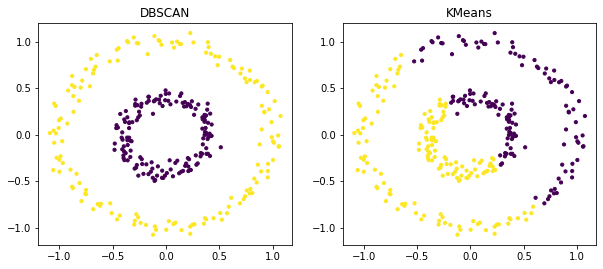

In [ ]:
import pandas as pd
from sklearn.datasets import make_circles
from sklearn.cluster import DBSCAN, KMeans
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_circles
from sklearn.cluster import DBSCAN, KMeans
import matplotlib.pyplot as plt
X, _ = make_circles(n_samples=300, noise=0.05, factor=0.4, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
dbscan = DBSCAN(eps=0.2, min_samples=5)
dbscan.fit(X)
kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
kmeans.fit(X)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.scatter(X['x1'], X['x2'], c=dbscan.labels_, s=10)
plt.title('DBSCAN')
plt.subplot(1, 2, 2)
plt.scatter(X['x1'], X['x2'], c=kmeans.labels_, s=10)
plt.title('KMeans')
plt.show()
```

</details>

#### Aufgabe 4.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.cluster import DBSCAN

X = pd.DataFrame({'x': [1.0, 1.1, 1.2, 5.0, 5.1, 5.2, 9.0]})
modell = DBSCAN(eps=0.3, min_samples=2)
modell.fit(X)
print(modell.labels_)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
[ 0  0  0  1  1  1 -1]
```

Die Punkte 1.0, 1.1, 1.2 liegen dicht beieinander (Abstände 0.1), ebenso 5.0, 5.1, 5.2. Das sind zwei Cluster mit den Nummern 0 und 1.
Der Punkt 9.0 hat keinen Nachbarn im Abstand 0.3 und ist Rauschen: `[ 0  0  0  1  1  1 -1]`.

</details>

## 5. Dimensionen reduzieren: PCA

#### Hauptkomponenten

Daten mit vielen Merkmalen (Wein: 13, Ziffern: 64) kann man nicht direkt zeichnen. Die **Hauptkomponentenanalyse** (*principal component analysis*, PCA)
sucht neue Achsen, die **Hauptkomponenten**: Die erste zeigt in die Richtung, in der die Punkte am meisten streuen, die zweite steht senkrecht darauf und
erfasst den größten Teil der restlichen Streuung, und so weiter. Projiziert man die Punkte auf die ersten zwei Achsen, erhält man ein Bild der Daten
in 2D, in dem möglichst viel der ursprünglichen Unterschiede erhalten ist.

- `PCA(n_components=2).fit_transform(X)` liefert für jede Zeile die zwei neuen Koordinaten.
- `explained_variance_ratio_` gibt an, welcher Anteil der Streuung auf jede Hauptkomponente entfällt.
- Vorher sollte man skalieren, sonst bestimmt das Merkmal mit den größten Zahlen alles.

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
import matplotlib.pyplot as plt

X_skaliert = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_skaliert)
print(X_2d.shape)
print(pca.explained_variance_ratio_.round(3))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, s=12)
plt.xlabel('1. Hauptkomponente')
plt.ylabel('2. Hauptkomponente')
plt.show()

#### Aufgabe 5.1

Reduziere die vier skalierten Iris-Maße mit PCA auf 2 Dimensionen. Gib die Anteile der Streuung beider Hauptkomponenten und ihre Summe aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
[0.73  0.229]
0.958
```

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
pca = PCA(n_components=2)
pca.fit(StandardScaler().fit_transform(X))
print(pca.explained_variance_ratio_.round(3))
print(f'{pca.explained_variance_ratio_.sum():.3f}')
```

</details>

#### Aufgabe 5.2

Zeichne die Iris-Blüten in den ersten beiden Hauptkomponenten (skaliert), jede Art in einer eigenen Farbe mit Legende (Schleife über die Arten).

**Erwartete Ausgabe:**



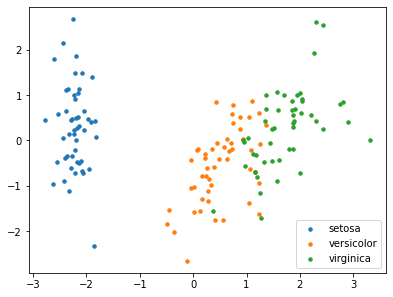

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
X_2d = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X))
for art in ['setosa', 'versicolor', 'virginica']:
    auswahl = (iris['art'] == art).to_numpy()
    plt.scatter(X_2d[auswahl, 0], X_2d[auswahl, 1], label=art, s=12)
plt.legend()
plt.show()
```

</details>

#### Aufgabe 5.3

Wie viele Hauptkomponenten braucht man für die skalierten Wein-Daten, um 90 % der Streuung zu erfassen? Berechne PCA mit allen 13 Komponenten, gib die
kumulierten Anteile aus (`np.cumsum()`, 3 Nachkommastellen) und die kleinste Anzahl mit mindestens 0.9.

**Erwartete Ausgabe:**

```
[0.362 0.554 0.665 0.736 0.802 0.851 0.893 0.92  0.942 0.962 0.979 0.992
 1.   ]
8
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
import numpy as np
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
import numpy as np
pca = PCA()
pca.fit(StandardScaler().fit_transform(X))
kumuliert = np.cumsum(pca.explained_variance_ratio_)
print(kumuliert.round(3))
print(np.argmax(kumuliert >= 0.9) + 1)
```

</details>

#### Aufgabe 5.4

Mit `PCA(n_components=0.9)` wählt scikit-learn selbst so viele Komponenten, dass mindestens 90 % der Streuung erfasst werden. Gib für die skalierten Wein-Daten
die Anzahl (`pca.n_components_`) und die Form der transformierten Daten aus.

**Erwartete Ausgabe:**

```
8
(178, 8)
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
pca = PCA(n_components=0.9)
X_neu = pca.fit_transform(StandardScaler().fit_transform(X))
print(pca.n_components_)
print(X_neu.shape)
```

</details>

#### Aufgabe 5.5

Hilft PCA beim Klassifizieren? Vergleiche mit 5-facher Kreuzvalidierung auf den Wein-Daten zwei Pipelines: `StandardScaler` + k-NN (`k = 5`) und
`StandardScaler` + `PCA(n_components=2)` + k-NN. Gib beide Mittelwerte aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
0.949
0.966
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
ohne = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
mit = make_pipeline(StandardScaler(), PCA(n_components=2), KNeighborsClassifier(n_neighbors=5))
print(f'{cross_val_score(ohne, X, y, cv=5).mean():.3f}')
print(f'{cross_val_score(mit, X, y, cv=5).mean():.3f}')
```

</details>

#### Aufgabe 5.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from sklearn.decomposition import PCA

X = np.array([[0, 0], [1, 1], [2, 2], [3, 3]])
pca = PCA(n_components=2)
pca.fit(X)
print(pca.explained_variance_ratio_.round(3))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
[1. 0.]
```

Alle Punkte liegen auf der Geraden `y = x`. Die erste Hauptkomponente zeigt genau in diese Richtung und erfasst die ganze Streuung,
senkrecht dazu streut nichts: `[1. 0.]`.

</details>

## 6. Projekt: Ziffern erkennen

#### Die Ziffern-Daten

`load_digits()` kennst du aus Notebook 2: 1797 Bilder mit 8 × 8 Pixeln, die Helligkeiten 0 bis 16 als Zeilen mit 64 Zahlen (`data`), die Bilder als 8 × 8-Arrays (`images`)
und die richtigen Ziffern (`target`). In diesem Abschnitt setzt du alles ein, was du in der Reihe gelernt hast.

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
import matplotlib.pyplot as plt

print(X.shape, np.bincount(y))
plt.figure(figsize=(8, 2))
for i in range(16):
    plt.subplot(2, 8, i + 1)
    plt.imshow(ziffern.images[i], cmap='gray_r')
    plt.axis('off')
plt.show()

#### Aufgabe 6.1

Zeige das „mittlere Bild“ jeder Ziffer: Berechne für jede Ziffer `z` den Mittelwert aller Zeilen mit `y == z` (`X[y == z].mean(axis=0).reshape(8, 8)`) und zeige
die zehn Bilder nebeneinander mit der Ziffer als Titel.

**Erwartete Ausgabe:**



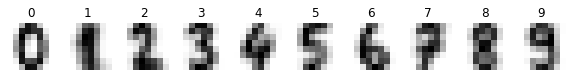

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 2))
for z in range(10):
    plt.subplot(1, 10, z + 1)
    plt.imshow(X[y == z].mean(axis=0).reshape(8, 8), cmap='gray_r')
    plt.title(z)
    plt.axis('off')
plt.show()
```

</details>

#### Aufgabe 6.2

Vergleiche drei Verfahren auf den Ziffern: k-NN (`k = 3`), skalierte logistische Regression (`max_iter=2000`) und skaliertes neuronales Netz (`(64,)`, `max_iter=300`,
`random_state=0`). Trainiere mit den Trainingsdaten und gib Namen und Test-Genauigkeit aus (3 Nachkommastellen). Das dauert einige Sekunden.

**Erwartete Ausgabe:**

```
k-NN 0.987
logistisch 0.967
Netz 0.971
```

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
modelle = {'k-NN': KNeighborsClassifier(n_neighbors=3),
           'logistisch': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
           'Netz': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=0))}
for name, modell in modelle.items():
    modell.fit(X_train, y_train)
    print(name, f'{modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 6.3

Zeichne die Konfusionsmatrix des k-NN-Modells (`k = 3`) für die Testdaten mit `ConfusionMatrixDisplay.from_predictions()`.

**Erwartete Ausgabe:**



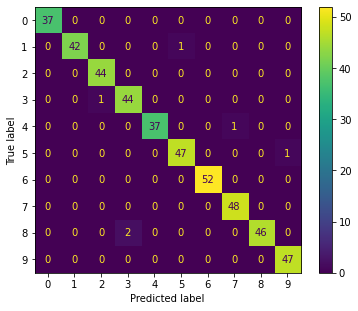

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
modell = KNeighborsClassifier(n_neighbors=3)
modell.fit(X_train, y_train)
ConfusionMatrixDisplay.from_predictions(y_test, modell.predict(X_test))
plt.show()
```

</details>

#### Aufgabe 6.4

Zeichne die Ziffern in 2D: Reduziere **alle** 1797 Bilder mit PCA auf 2 Dimensionen und zeichne die Punkte gefärbt nach der Ziffer (`c=y`, `cmap='tab10'`,
`s=5`) mit einer Farbleiste (`plt.colorbar()`). Manche Ziffern bilden deutliche Gruppen.

**Erwartete Ausgabe:**



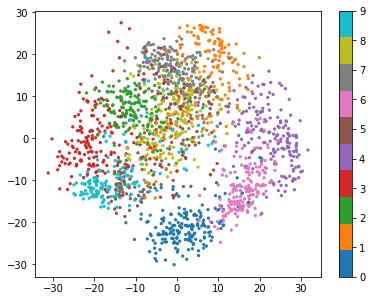

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
X_2d = PCA(n_components=2).fit_transform(X)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap='tab10', s=5)
plt.colorbar()
plt.show()
```

</details>

#### Aufgabe 6.5

Wie viele Hauptkomponenten braucht man, um 90 % der Streuung der Ziffern zu erfassen (`PCA(n_components=0.9)` auf allen Bildern)? Trainiere danach eine Pipeline aus
dieser PCA und k-NN (`k = 3`) mit den Trainingsdaten und gib die Test-Genauigkeit aus (3 Nachkommastellen). Mit viel weniger Merkmalen ist sie fast genauso gut.

**Erwartete Ausgabe:**

```
21
0.984
```

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
pca = PCA(n_components=0.9)
pca.fit(X)
print(pca.n_components_)
modell = make_pipeline(PCA(n_components=0.9), KNeighborsClassifier(n_neighbors=3))
modell.fit(X_train, y_train)
print(f'{modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 6.6

Kann KMeans die Ziffern **ohne** die Lösungen sortieren? Bilde 10 Cluster aus allen Bildern und zeige die Mittelpunkte der Cluster als Bilder
(`modell.cluster_centers_[i].reshape(8, 8)`) mit der Clusternummer als Titel an. Bei 64 Merkmalen hängt das Ergebnis von kleinsten Rechenunterschieden ab;
deshalb gibt es hier und in der nächsten Aufgabe keine erwartete Ausgabe, nur eine Beispiellösung.

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
modell = KMeans(n_clusters=10, n_init=10, random_state=0)
modell.fit(X)
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(modell.cluster_centers_[i].reshape(8, 8), cmap='gray_r')
    plt.title(i)
    plt.axis('off')
plt.show()
```

</details>

#### Aufgabe 6.7

Vergleiche die 10 Cluster der vorigen Aufgabe mit den echten Ziffern: Zeige die Kreuztabelle `pd.crosstab(y, modell.labels_)` an.
In vielen Zeilen landet fast alles in einem Cluster.

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import pandas as pd
from sklearn.cluster import KMeans
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import pandas as pd
from sklearn.cluster import KMeans
modell = KMeans(n_clusters=10, n_init=10, random_state=0)
modell.fit(X)
pd.crosstab(y, modell.labels_)
```

</details>

#### Aufgabe 6.8

Zeichne selbst eine Ziffer: Die Liste `bild` in der Zelle enthält 8 Zeilen mit je 8 Helligkeiten (0 bis 16) und zeigt eine 7. Zeige das Bild an und lass
das neuronale Netz (skaliert, `(64,)`, `max_iter=300`, `random_state=0`, trainiert mit **allen** Bildern) die Ziffer erkennen
(`np.array(bild).reshape(1, 64)` macht daraus eine Zeile mit 64 Merkmalen). Gib auch die drei wahrscheinlichsten Ziffern mit ihren Wahrscheinlichkeiten aus
(`np.argsort()` sortiert aufsteigend, 3 Nachkommastellen).

**Erwartete Ausgabe:**

```
[7]
7 0.987
2 0.006
4 0.005
```

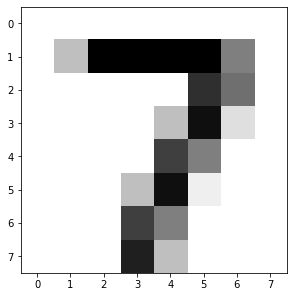

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

bild = [[0, 0, 0, 0, 0, 0, 0, 0],
        [0, 4, 16, 16, 16, 16, 8, 0],
        [0, 0, 0, 0, 0, 13, 9, 0],
        [0, 0, 0, 0, 4, 15, 2, 0],
        [0, 0, 0, 0, 12, 8, 0, 0],
        [0, 0, 0, 4, 15, 1, 0, 0],
        [0, 0, 0, 12, 8, 0, 0, 0],
        [0, 0, 0, 14, 4, 0, 0, 0]]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

bild = [[0, 0, 0, 0, 0, 0, 0, 0],
        [0, 4, 16, 16, 16, 16, 8, 0],
        [0, 0, 0, 0, 0, 13, 9, 0],
        [0, 0, 0, 0, 4, 15, 2, 0],
        [0, 0, 0, 0, 12, 8, 0, 0],
        [0, 0, 0, 4, 15, 1, 0, 0],
        [0, 0, 0, 12, 8, 0, 0, 0],
        [0, 0, 0, 14, 4, 0, 0, 0]]
modell = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=0))
modell.fit(X, y)
zeile = np.array(bild).reshape(1, 64)
print(modell.predict(zeile))
wahrscheinlichkeiten = modell.predict_proba(zeile)[0]
for z in np.argsort(wahrscheinlichkeiten)[::-1][:3]:
    print(z, f'{wahrscheinlichkeiten[z]:.3f}')
plt.imshow(np.array(bild), cmap='gray_r')
plt.show()
```

</details>

#### Aufgabe 6.9

Suche mit `GridSearchCV` (3-fach, Ziffern-Trainingsdaten) die beste Anzahl von Neuronen (16, 32, 64) für ein skaliertes Netz (`max_iter=1000`, `random_state=0`).
Gib die besten Einstellungen und die Test-Genauigkeit des besten Modells aus (3 Nachkommastellen). Das dauert etwas länger, weil 9 Netze trainiert werden.

**Erwartete Ausgabe:**

```
{'mlpclassifier__hidden_layer_sizes': (32,)}
0.971
```

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
modell = make_pipeline(StandardScaler(), MLPClassifier(max_iter=1000, random_state=0))
gitter = {'mlpclassifier__hidden_layer_sizes': [(16,), (32,), (64,)]}
suche = GridSearchCV(modell, gitter, cv=3)
suche.fit(X_train, y_train)
print(suche.best_params_)
print(f'{suche.best_estimator_.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 6.10

Zeichne eigene Ziffern (z. B. eine 1, eine 4 und eine 8) als 8 × 8-Listen wie oben und prüfe, ob das Netz sie erkennt. Welche Ziffern sind schwer?

In [ ]:
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from sklearn.datasets import load_digits
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ziffern = load_digits()
modell = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=0))
modell.fit(ziffern.data, ziffern.target)
eins = [[0, 0, 0, 8, 12, 0, 0, 0],
        [0, 0, 6, 16, 12, 0, 0, 0],
        [0, 0, 0, 12, 12, 0, 0, 0],
        [0, 0, 0, 12, 12, 0, 0, 0],
        [0, 0, 0, 12, 12, 0, 0, 0],
        [0, 0, 0, 12, 12, 0, 0, 0],
        [0, 0, 0, 12, 12, 0, 0, 0],
        [0, 0, 4, 16, 16, 4, 0, 0]]
print(modell.predict(np.array(eins).reshape(1, 64)))
```

</details>